# Exploratory Data Analysis on Retail Sales Data

## Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on retail sales data to identify sales patterns, customer behaviour, product-category performance, and actionable business insights.

## Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("retail_sales_dataset.csv")

## Initial Dataset Inspection

The dataset is loaded and its structure is examined before performing analysis.

In [5]:
df.head(15)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


In [6]:
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [7]:
df.shape

(1000, 9)

In [9]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

In [11]:
df.dtypes

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [13]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

### Initial Inspection Observation

- The dataset contains **1,000 rows and 9 columns**.
- All 9 columns contain complete values, with **no missing values**.
- There are **no duplicate records**.
- The dataset contains numerical variables such as Age, Quantity, Price per Unit, and Total Amount, along with categorical variables such as Gender and Product Category.

In [15]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [16]:
numeric_cols = df.select_dtypes(include=np.number).columns

numeric_cols

Index(['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount'], dtype='str')

In [17]:
df[numeric_cols].mean()

Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

In [18]:
df[numeric_cols].median()

Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

In [19]:
df[numeric_cols].mode().iloc[0]

Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

In [20]:
df[numeric_cols].std()

Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

In [21]:
statistics = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std()
})

statistics

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


## Descriptive Statistics

The mean, median, mode, and standard deviation are calculated for all numerical variables to understand their central tendency and variability.

In [22]:
df["Date"] = pd.to_datetime(df["Date"])

In [23]:
df["Date"].dtype

dtype('<M8[us]')

In [24]:
df["Month"] = df["Date"].dt.to_period("M")

In [25]:
df["Quarter"] = df["Date"].dt.to_period("Q")

## Time-Series Analysis

The Date column is converted into a datetime format, and Month and Quarter fields are created to analyze sales over time.

In [26]:
monthly_sales = df.groupby("Month")["Total Amount"].sum()

monthly_sales

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

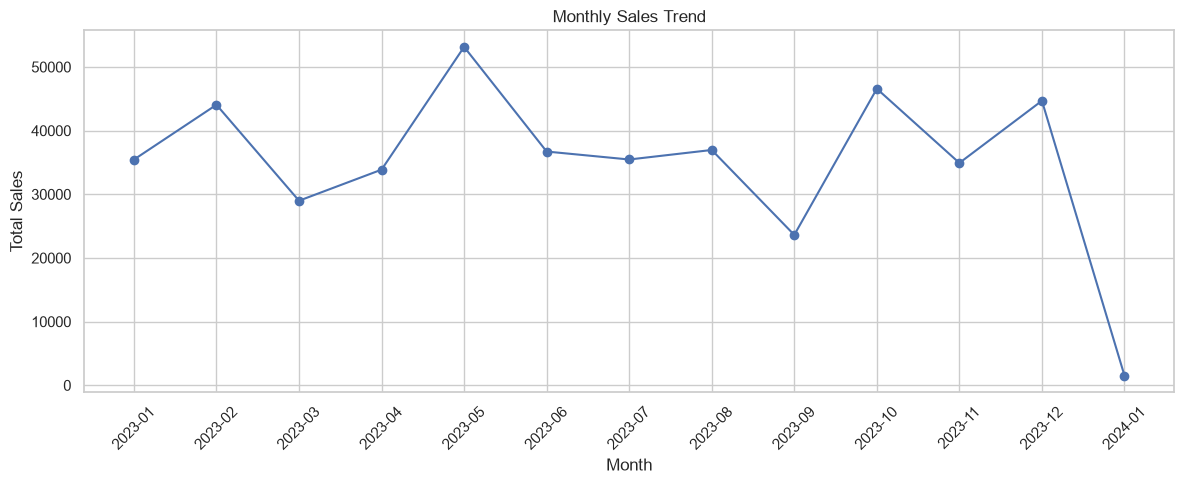

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Monthly Sales Trend — Observation

Monthly sales vary throughout the observed period. **May 2023 recorded the highest monthly sales (53,150)**, while **September 2023 recorded the lowest (23,620)** among the 2023 months. The January 2024 value is only 1,530, which appears to represent a partial period, so it should not be compared directly with full months when making business decisions.

In [28]:
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

quarterly_sales

Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

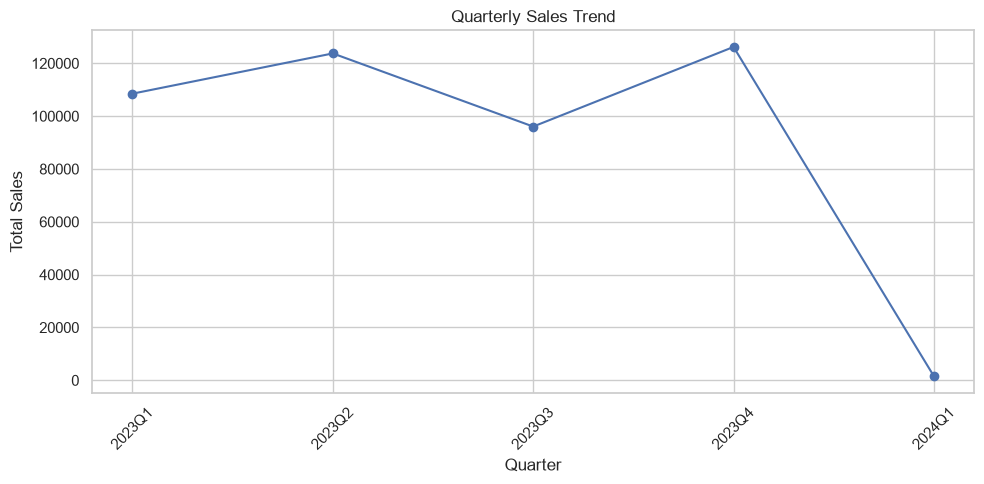

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker="o"
)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Quarterly Sales Trend — Observation

Quarterly sales were highest in **Q4 2023 (126,190)**, followed by **Q2 2023 (123,735)**. **Q3 2023 recorded the lowest full-quarter sales (96,045)**. Q1 2024 is incomplete because it contains only January data.

In [30]:
df["Age"].describe()

count    1000.00000
mean       41.39200
std        13.68143
min        18.00000
25%        29.00000
50%        42.00000
75%        53.00000
max        64.00000
Name: Age, dtype: float64

In [31]:
bins = [0, 18, 25, 35, 45, 55, 65, 100]

labels = [
    "Under 18",
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "65+"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)

In [32]:
age_counts = df["Age Group"].value_counts().sort_index()

age_counts

Age Group
Under 18     21
18-25       148
26-35       205
36-45       202
46-55       229
56-65       195
65+           0
Name: count, dtype: int64

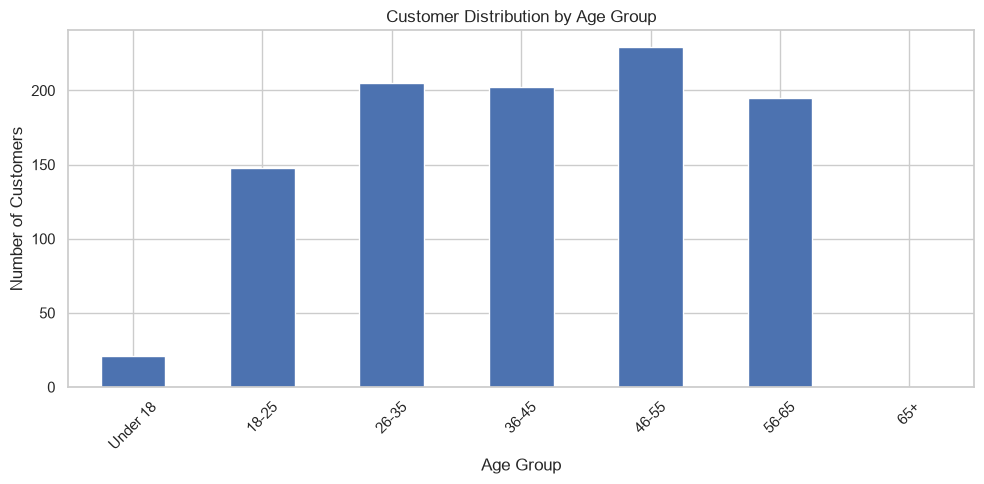

In [33]:
plt.figure(figsize=(10, 5))

age_counts.plot(kind="bar")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Customer Age Distribution — Observation

The largest customer age group is **46–55 years (229 customers)**, followed by **26–35 years (205 customers)** and **36–45 years (202 customers)**. The dataset contains ages from 18 to 64, so the Under 18 and 65+ buckets are not populated meaningfully.

In [34]:
gender_counts = df["Gender"].value_counts()

gender_counts

Gender
Female    510
Male      490
Name: count, dtype: int64

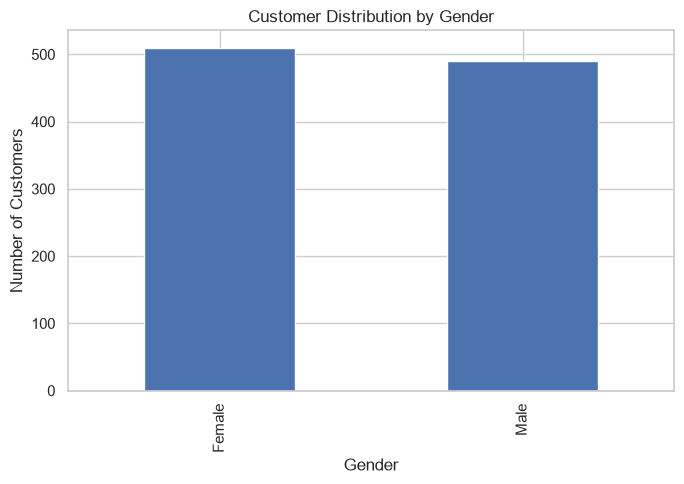

In [35]:
plt.figure(figsize=(7, 5))

gender_counts.plot(kind="bar")

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Gender Distribution — Observation

The dataset contains **510 female** and **490 male** customer records. The distribution is relatively balanced, with female customers representing a slightly larger share of transactions.

In [36]:
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

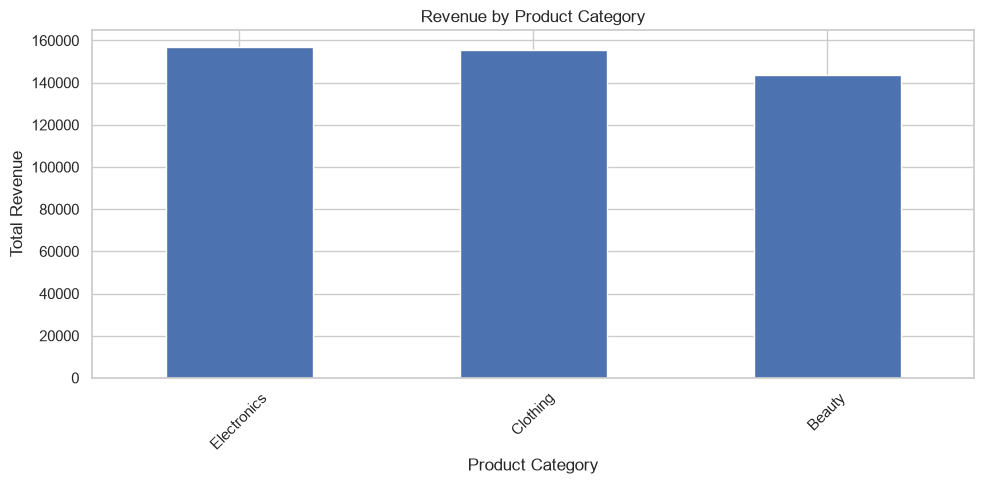

In [37]:
plt.figure(figsize=(10, 5))

category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Product Category Revenue Analysis

Because the dataset does not contain an individual Product or Product Name column, product-level top-10 analysis cannot be performed without inventing information. The analysis therefore uses Product Category, which is the most detailed product field available.

### Observation

**Electronics generated the highest revenue (156,905)**, followed by **Clothing (155,580)** and **Beauty (143,515)**. Electronics and Clothing are very close in total revenue, while Beauty contributes less revenue than the other two categories.

In [42]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.000000,0.065191,-0.026623,-0.060837,-0.075034
Age,0.065191,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.026623,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.060837,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.075034,-0.060568,0.373707,0.851925,1.000000


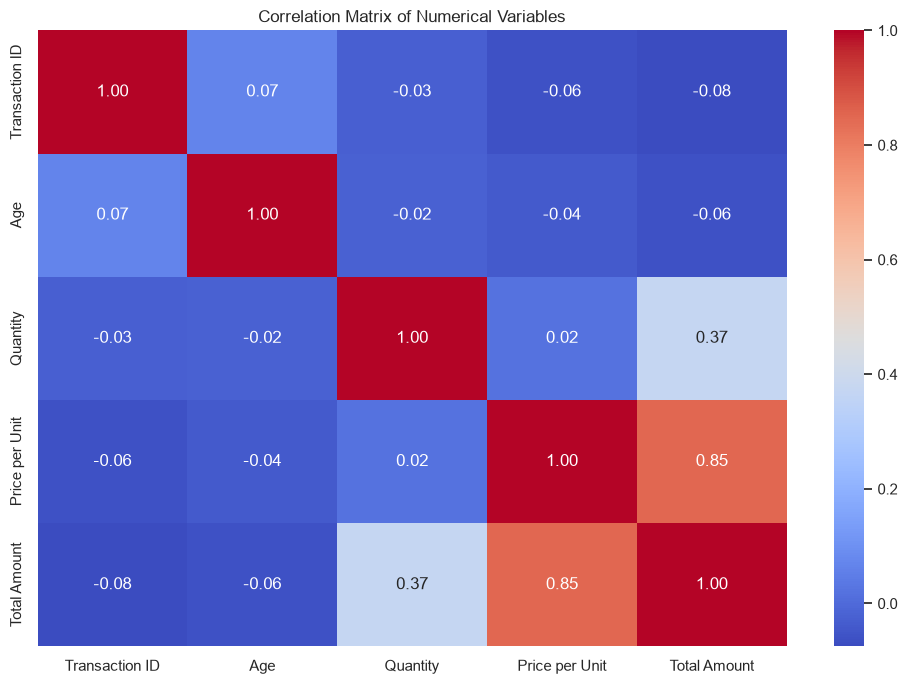

In [43]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

### Correlation Heatmap — Observation

The strongest relationship with Total Amount is **Price per Unit (correlation ≈ 0.852)**, followed by **Quantity (≈ 0.374)**. This indicates that transaction value is strongly associated with unit price in this dataset, while quantity has a moderate positive relationship with transaction value. Age has a very weak negative relationship with Total Amount (≈ -0.061).

In [44]:
avg_spending_age = (
    df.groupby("Age Group", observed=True)["Total Amount"]
    .mean()
)

avg_spending_age

Age Group
Under 18    534.047619
18-25       495.506757
26-35       480.390244
36-45       454.801980
46-55       439.694323
56-65       412.358974
Name: Total Amount, dtype: float64

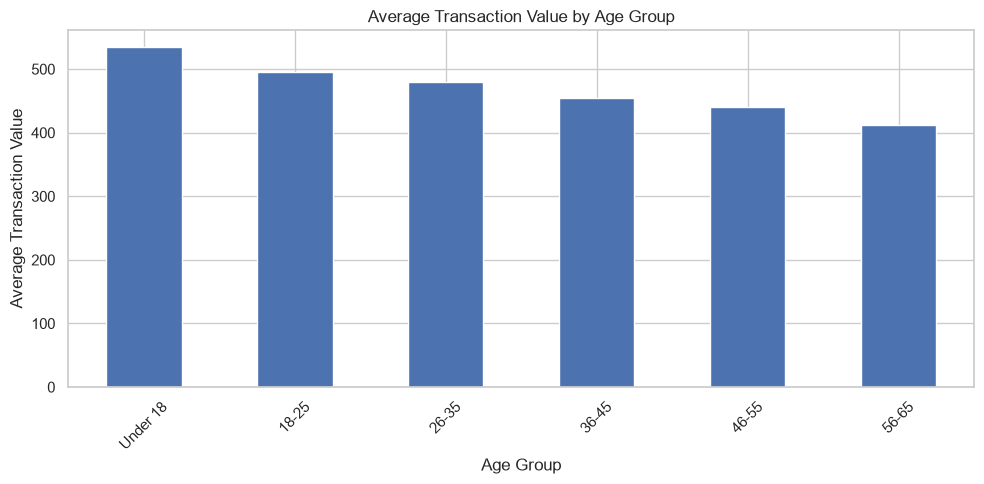

In [45]:
plt.figure(figsize=(10, 5))

avg_spending_age.plot(kind="bar")

plt.title("Average Transaction Value by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Value")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Additional Visualization: Average Transaction Value by Age Group

This visualization provides a non-obvious insight by comparing customer spending per transaction rather than simply counting customers.

**Observation:** Average transaction value is highest for the age-18 observations represented by the **Under 18** bucket (≈534.05), followed by **18–25 (≈495.51)**, and declines across older groups to approximately **412.36 for 56–65**. Because the dataset minimum age is 18, the Under 18 label is a binning artifact; it should be interpreted as age-18 customers rather than customers below 18.

In [46]:
category_quantity = (
    df.groupby("Product Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

category_quantity

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

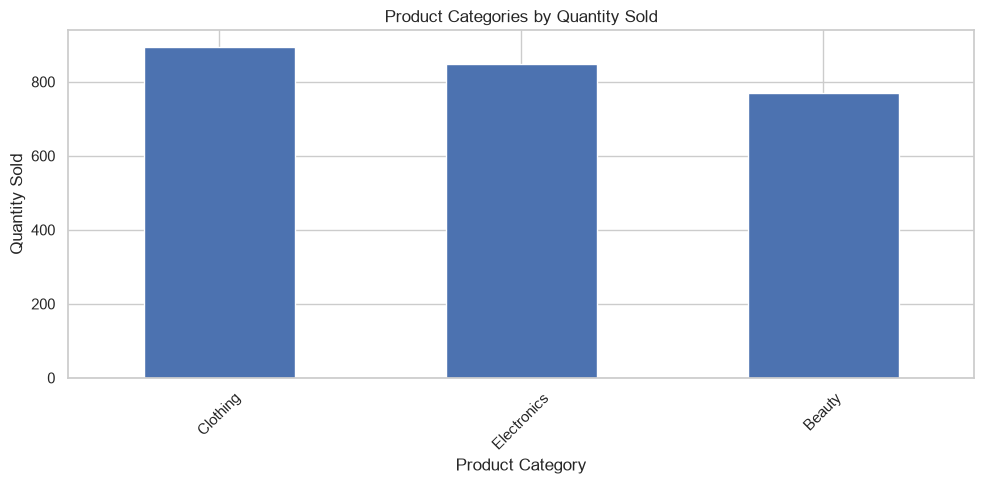

In [47]:
plt.figure(figsize=(10, 5))

category_quantity.plot(kind="bar")

plt.title("Product Categories by Quantity Sold")
plt.xlabel("Product Category")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Product Category Quantity Analysis — Observation

**Clothing has the highest quantity sold (894 units)**, followed by **Electronics (849 units)** and **Beauty (771 units)**. This differs slightly from the revenue ranking, where Electronics is first. This shows why both quantity and revenue should be considered when evaluating category performance.

# Conclusion and Business Recommendations

## Key Findings

- The dataset contains **1,000 transactions** with no missing values or duplicate records.
- **May 2023** had the highest monthly sales at **53,150**, while **September 2023** had the lowest full-month sales at **23,620**.
- **Q4 2023** had the highest full-quarter sales at **126,190**.
- **Electronics** generated the highest category revenue at **156,905**, while **Clothing** recorded the highest quantity sold at **894 units**.
- **Price per Unit** has a strong positive correlation with **Total Amount (≈0.852)**.

## Actionable Business Recommendations

### 1. Prioritize Electronics and Clothing

Electronics generated the highest revenue, while Clothing recorded the highest quantity sold. The business should maintain strong inventory availability for both categories and use category-specific promotions rather than relying on a single performance measure.

### 2. Plan Inventory and Promotions Around Demand Patterns

May 2023 and Q4 2023 showed stronger sales, while September 2023 was weaker. The business can use these observed patterns to plan inventory, staffing, and promotional campaigns before higher-demand periods and investigate the causes of weaker periods.

### 3. Use Customer Spending Patterns for Targeted Marketing

Average transaction value differs across age groups. The business can identify higher-value segments and test personalized offers or loyalty campaigns, while evaluating campaign performance using actual transaction value rather than customer count alone.

### 4. Review Pricing and Product Mix

Total Amount has a strong positive correlation with Price per Unit. The business should monitor pricing and product mix carefully and evaluate whether higher-value transactions are driven by price, quantity, or both.

## Overall Conclusion

The EDA reveals meaningful differences in sales over time, customer demographics, category revenue, quantity sold, and transaction value. These findings can support data-driven decisions around inventory planning, promotions, customer targeting, and pricing strategy.

**Dataset limitation:** The dataset does not contain individual product names, so a true Top 10 Products analysis is not possible. Product performance was therefore evaluated at the Product Category level using quantity sold and revenue.